# Student Peformance Prediction EDA

## Problem Statement 
Secondary schools often identify struggling students only after poor grades have already appeared, leaving little time to intervene. This project builds a classification model that takes student demographic, family, and behavioral features and predicts whether a student will pass (G3 ≥ 10) or fail (G3 < 10). Success is measured primarily by recall on the "fail" class, with precision, F1, and ROC-AUC as secondary metrics.

## Dataset
- **Source:** [UCI Machine Learning Repository, Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)
- **Reference:** Cortez, P. & Silva, A. (2008). *Using Data Mining to Predict Secondary School Student Performance.*
- **Size:** 649 records (Portuguese).
- **Features:** demographics, family background, study habits, absences, alcohol consumption, school support, and prior grades (G1, G2).
- **Target:** binary pass/fail derived from final grade G3.

### Importing standard libraries 

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

%matplotlib inline

### Load Data

In [3]:
student_df = pd.read_csv("Data/student-por.csv")

In [4]:
student_df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [5]:
student_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [6]:
student_df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


### Handling missing values 

In [7]:
student_df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

**Insights** \
No missing values available in dataset

In [9]:
## checking for duplicates 
print(f"Number of duplicates datapoint: {student_df.duplicated().sum()}")

Number of duplicates datapoint: 0


## Data Visualization 

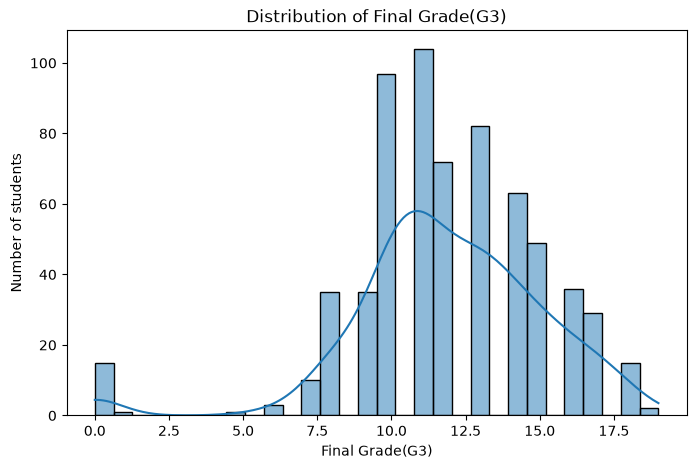

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(student_df["G3"] , bins=30, kde=True)
plt.title("Distribution of Final Grade(G3)")
plt.ylabel("Number of students")
plt.xlabel("Final Grade(G3)")
plt.show()

**Insights**\
The distribution of final grades is centered around 10-12, with most students clustering near the pass threshold. However, a small, isolated group of about 15 students scored 0, separated from the main distribution by a gap of near-empty bins. This pattern points to non-completion rather than low performance, so these records should be treated as a separate group in further analysis. Using the median rather than the mean, and investigating prior-term grades and absences for this group, would give a more accurate picture of student performance.

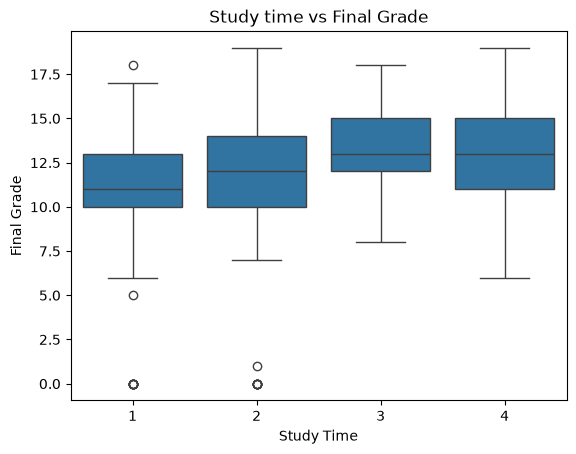

In [16]:
sns.boxplot(x="studytime", y="G3", data=student_df)
plt.title("Study time vs Final Grade")
plt.ylabel("Final Grade")
plt.xlabel("Study Time")
plt.show()

**Insights** \
Final grades rise with study time, from a median of about 11 in the lowest group to about 13 in groups 3 and 4, but the gain levels off beyond the third category. Low-study groups also contain nearly all of the zero-grade outliers, suggesting disengagement rather than low ability. Because the distributions overlap substantially, study time explains only part of the variation in performance, and further analysis should control for absences and prior grades before drawing conclusions about its effect.

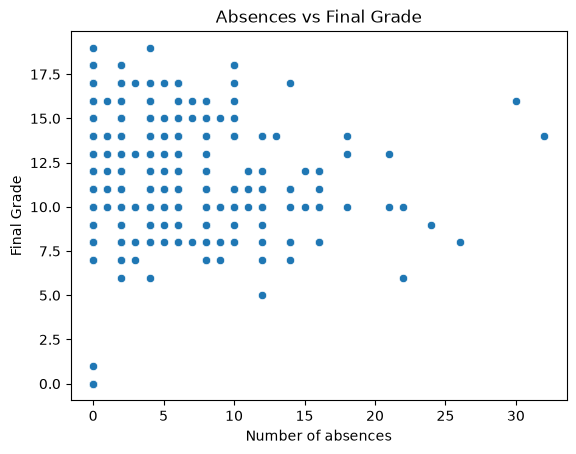

In [19]:
sns.scatterplot(x="absences", y="G3", data=student_df)
plt.title("Absences vs Final Grade")
plt.ylabel("Final Grade")
plt.xlabel("Number of absences")
plt.show()

**Insights**\
There is little visible relationship between the number of absences and final grade. Students with few and many absences achieve similar grades, mostly between 8 and 14, though high-absence observations are rare, which limits confidence at that end. Two students with zero absences and near-zero grades stand out as likely data or non-completion anomalies. A correlation test, a density-aware plot, and analysis with the zero-grade records excluded are recommended before concluding that attendance has no effect.

C:\Users\Adam\AppData\Local\Temp\ipykernel_7516\844431302.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="sex", y="G3", data=student_df, palette='viridis')


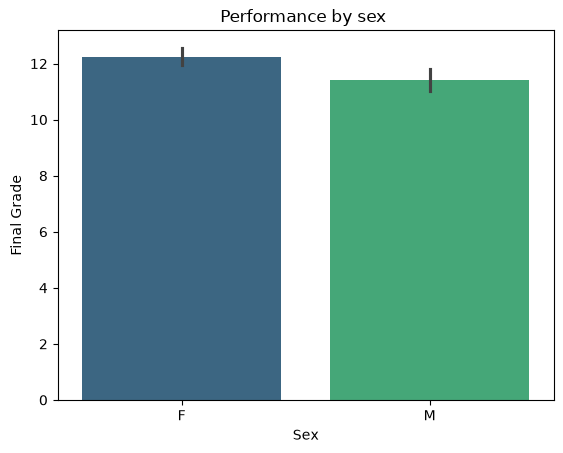

In [23]:
sns.barplot(x="sex", y="G3", data=student_df, palette='viridis')
plt.title("Performance by sex ")
plt.ylabel("Final Grade")
plt.xlabel("Sex")
plt.show()

**Insights**\
Female students have a slightly higher mean final grade (about 12.3) than male students (about 11.4), and the 95% confidence intervals barely separate. The difference is under one grade point on a 20-point scale, so it is small in practical terms, and the substantial overlap between individual students means sex is a weak predictor on its own. Because zero-grade records may influence the means, the comparison should be repeated with those excluded, tested formally with an effect size, and examined alongside study time and absences before drawing conclusions.

Text(0.5, 1.0, 'Correlation map of various numerical features')

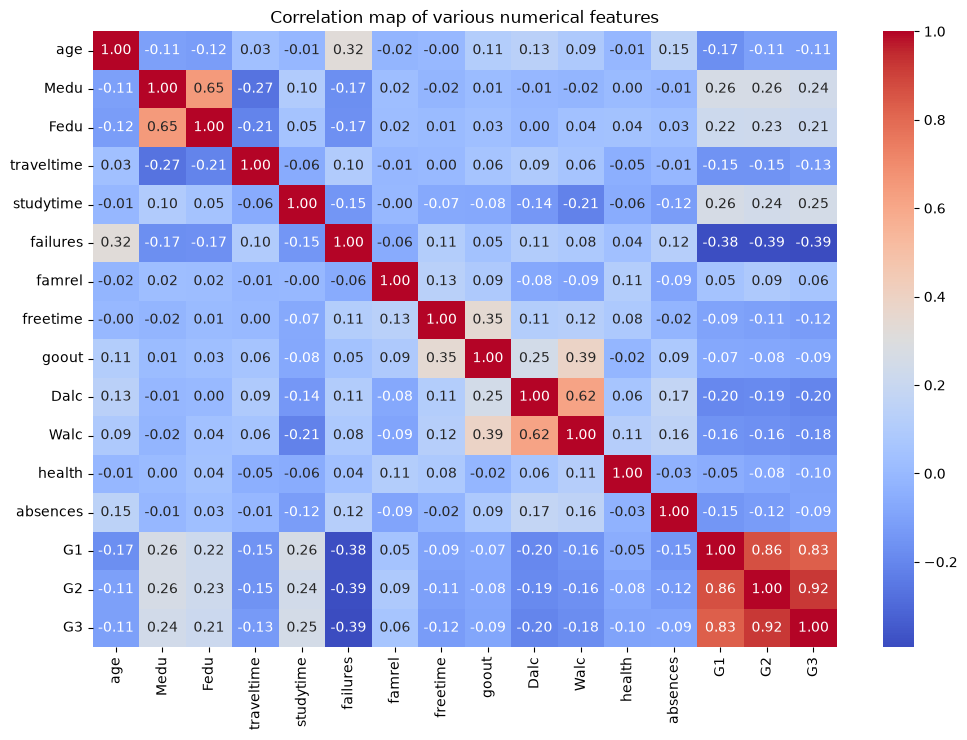

In [27]:
plt.figure(figsize=(12,8))
correlation = student_df.corr(numeric_only=True)
sns.heatmap(data=correlation, annot=True, cmap="coolwarm", fmt="0.2f")
plt.title("Correlation map of various numerical features")

**Insights** \
Final grade (G3) is almost entirely tied to earlier grades (G1 r = 0.83, G2 r = 0.92), so these should be treated separately from other predictors to avoid masking other effects. Among remaining features, past failures show the strongest association with G3 (r = -0.39), while study time and parental education show weak positive links (r ≈ 0.21 to 0.25). Absences, health and social variables are near zero, consistent with the earlier scatter and box plots. Several predictors are also correlated with each other (parental education, weekday and weekend alcohol use), which risks redundancy in modeling. Because these are linear coefficients on mostly ordinal data and the zero-grade records may distort them, the analysis should be repeated with rank correlations and with those records excluded.

## Conclusion
Students who have failed before and those who disengage entirely are the ones at risk. Study time matters somewhat, while attendance, health, and social factors matter little in this data. Early intervention should therefore target students with previous failures and low engagement